In [116]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
import numpy as np

In [117]:
# TO FILL

# Initialize the folders with train, test and validation datasets
# Paths are configured here for '/content/Cats_and_Dogs/'

train = 'Cats_and_Dogs/train'
val =   'Cats_and_Dogs/val'
test =  'Cats_and_Dogs/test'

# The shape of the RGB image
img_width, img_height, channels = 150, 150, 3  #У MobileNetV2 и VGG16 изображения 224х224

# input shape for PyTorch (channels first)
input_shape = (3, img_height, img_width)  # PyTorch uses (N, C, H, W) format for input data - (batch_size, channels, height, width)

# Set device (GPU if available, otherwise CPU)
device = 'cuda'
print(f"Using device: {device}")

# minibatch size. You can try 64 at first, and compare results with 16, 32, 128
batch_size = 64

Using device: cuda


In [118]:
# Define transforms for data preprocessing
# PyTorch transforms: resize, convert to tensor (scales to [0,1]), and normalize
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),  # Converts to tensor and scales to [0, 1]
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
    ])
}

# Create datasets using ImageFolder (expects subdirectories for each class)
train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

# Create data loaders
# Note: num_workers=2 for Colab (uses multiprocessing for faster data loading)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2,    pin_memory=True,
    persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2,    pin_memory=True,
    persistent_workers=True)

In [119]:
# TO FILL

# Define CNN model as a PyTorch class
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        # 1: Convolutional layer with 16 output channels, 3x3 kernel
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()

        # 2: MaxPooling layer with 2x2 kernel
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 3: Convolutional layer with 32 output channels
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()

        # 4: Pooling
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 5: Convolutional (64 channels)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()

        # 6: Pooling
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # 7: Flatten (handled in forward pass)
        self.flatten = nn.Flatten()

        # After 3 pooling layers: 150 -> 75 -> 37 -> 18
        # 8: Dense (Fully Connected) with 64 neurons
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()

        # 9: Dropout(0.5)
        self.dropout = nn.Dropout(0.5)

        # 10: Dense with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(64, 1) #Долго думал, пока не вспомнил что это работает как вход - выход, если прошлый слой был на выходе 64, то на следующий надо указывать на вход 64
        

    def forward(self, x):
        # Forward pass through the network
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        # Flatten: convert (batch, channels, h, w) to (batch, channels*h*w)
        x = x.view(x.size(0), -1)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

# Instantiate the model and move to device
model = CNNModel().to(device)
print(model)


CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [120]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
# Note: If using BCEWithLogitsLoss, remove sigmoid from model's last layer
criterion = nn.BCEWithLogitsLoss()
# Alternatively: use nn.BCELoss() if you keep sigmoid in the model

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [121]:

# Training loop for PyTorch

# you can try different number of epochs: 10, 15, 20; check the learning curves, loss and accuracy;
num_epochs =  10

# Lists to store training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Main training loop
for epoch in range(num_epochs):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%') #Соболезную людям без видеокарты

Epoch [1/10], Train Loss: 0.6753, Train Acc: 57.89%, Val Loss: 0.6387, Val Acc: 64.66%
Epoch [2/10], Train Loss: 0.6050, Train Acc: 67.25%, Val Loss: 0.5671, Val Acc: 70.48%
Epoch [3/10], Train Loss: 0.5472, Train Acc: 72.14%, Val Loss: 0.5223, Val Acc: 74.42%
Epoch [4/10], Train Loss: 0.4915, Train Acc: 76.36%, Val Loss: 0.4923, Val Acc: 76.67%
Epoch [5/10], Train Loss: 0.4466, Train Acc: 79.32%, Val Loss: 0.4809, Val Acc: 76.87%
Epoch [6/10], Train Loss: 0.4080, Train Acc: 81.53%, Val Loss: 0.4934, Val Acc: 76.59%
Epoch [7/10], Train Loss: 0.3737, Train Acc: 83.62%, Val Loss: 0.4474, Val Acc: 79.20%
Epoch [8/10], Train Loss: 0.3351, Train Acc: 85.38%, Val Loss: 0.4831, Val Acc: 79.16%
Epoch [9/10], Train Loss: 0.2934, Train Acc: 87.34%, Val Loss: 0.4931, Val Acc: 79.80%
Epoch [10/10], Train Loss: 0.2681, Train Acc: 88.86%, Val Loss: 0.4798, Val Acc: 79.44%


In [122]:
# Evaluate on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 82.00%


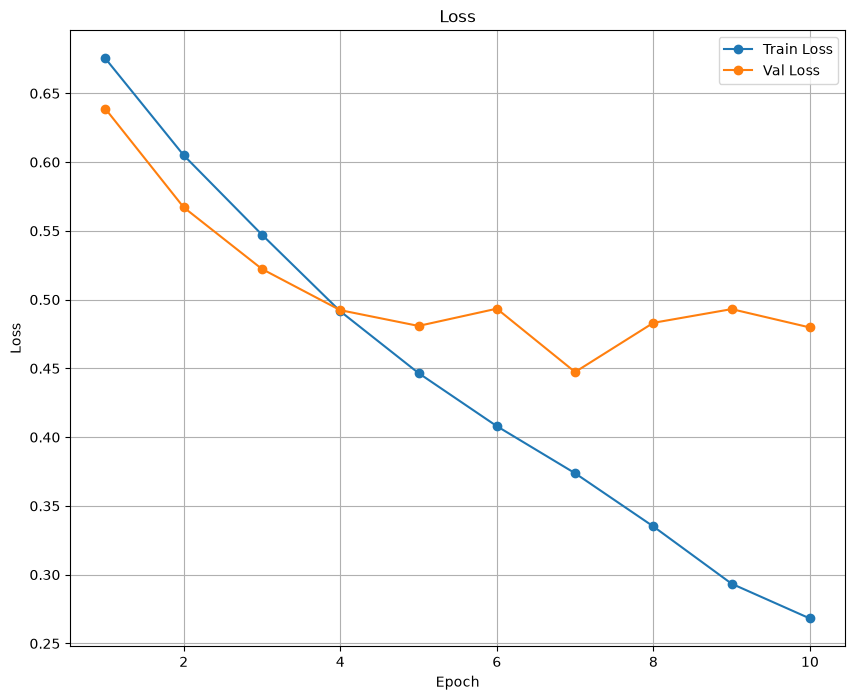

In [123]:
# TO FILL

import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 8))
plt.plot(epochs, train_losses, label='Train Loss', marker = 'o')
plt.plot(epochs, val_losses, label='Val Loss', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True)
plt.legend()
plt.show()

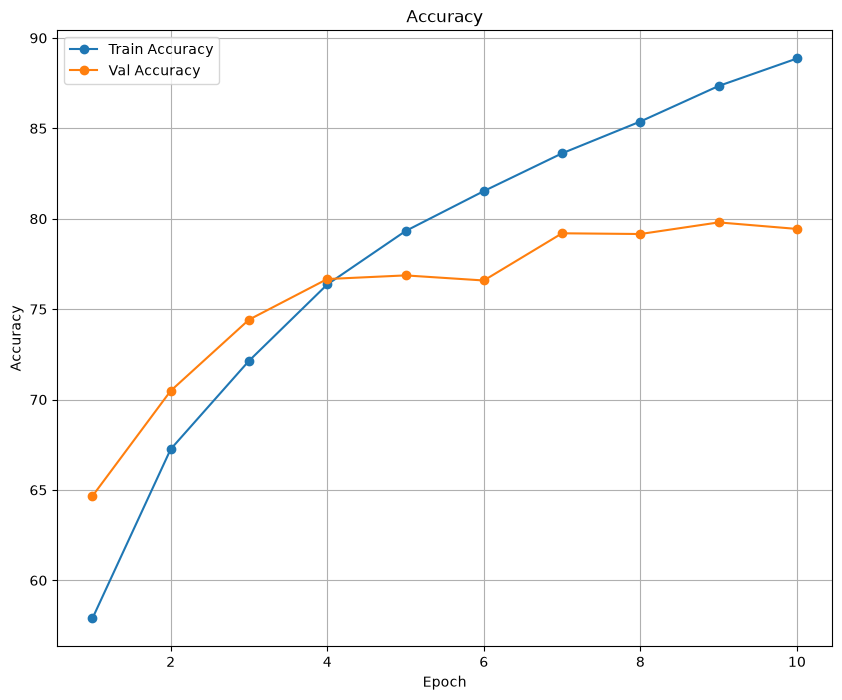

In [124]:
plt.figure(figsize=(10, 8))
plt.plot(epochs, train_accuracies, label='Train Accuracy', marker = 'o')
plt.plot(epochs, val_accuracies, label='Val Accuracy', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

In [125]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
# PyTorch will automatically download the weights when you first run this

vgg16_net = models.vgg16(pretrained=True)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze the weights - we do NOT want to retrain the VGG16 layers
# Weights VGG16 in the process of learning will remain unchanged!
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)  # pay attention to the architecture

c:\Users\timep\AppData\Local\Programs\Python\Python314\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\timep\AppData\Local\Programs\Python\Python314\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [126]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

modelVGG = VGG16TransferModel(vgg16_net).to(device)
print(modelVGG)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [127]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(modelVGG.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [128]:
# TO FILL

# Training loop for transfer learning model

num_epochs_transfer = 5

# Lists to store training history
train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

for epoch in range(num_epochs_transfer):
    modelVGG.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = modelVGG(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses_transfer.append(train_loss)
    train_accuracies_transfer.append(train_acc)

    # Validation phase
    modelVGG.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = modelVGG(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses_transfer.append(val_loss)
    val_accuracies_transfer.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%') #Соболезную людям без видеокарты x2
    #btw VGG-16 тяжелая модель для такой простой задачи, ResNet и MobileNet весят 20 мб вместо 500, и с таким датасетом справляются не хуже


Epoch [1/10], Train Loss: 0.1865, Train Acc: 93.14%, Val Loss: 0.1268, Val Acc: 95.10%
Epoch [2/10], Train Loss: 0.1214, Train Acc: 95.19%, Val Loss: 0.1123, Val Acc: 95.66%
Epoch [3/10], Train Loss: 0.1060, Train Acc: 95.85%, Val Loss: 0.1073, Val Acc: 95.82%
Epoch [4/10], Train Loss: 0.0965, Train Acc: 96.19%, Val Loss: 0.1028, Val Acc: 96.18%
Epoch [5/10], Train Loss: 0.0883, Train Acc: 96.64%, Val Loss: 0.1025, Val Acc: 95.86%


In [129]:
# Evaluate transfer learning model on test data
modelVGG.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = modelVGG(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%") #неплохо

Accuracy on test data: 95.00%


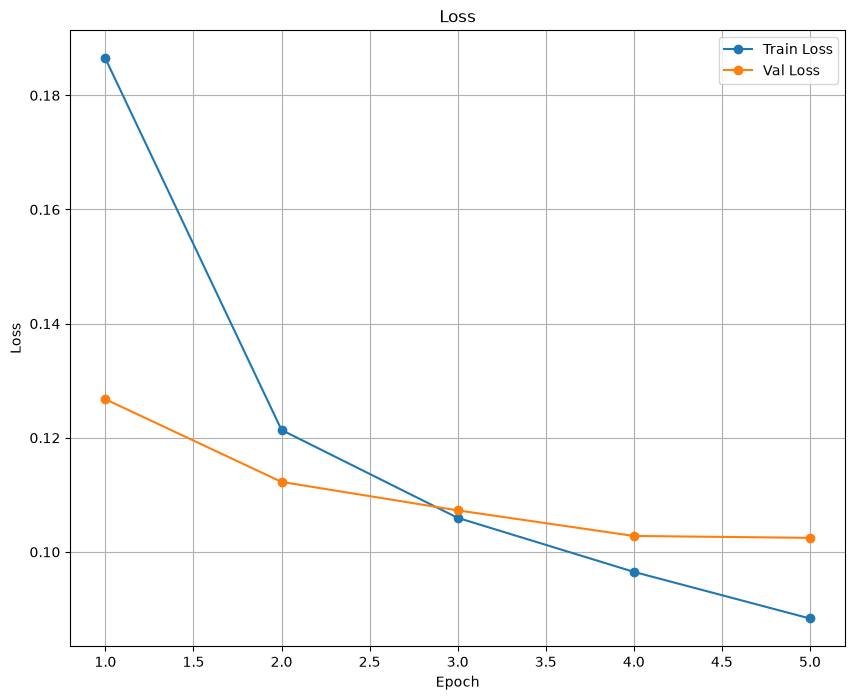

In [130]:
epochs = range(1, len(train_losses_transfer) + 1)

plt.figure(figsize=(10, 8))
plt.plot(epochs, train_losses_transfer, label='Train Loss', marker = 'o')
plt.plot(epochs, val_losses_transfer, label='Val Loss', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True)
plt.legend()
plt.show()

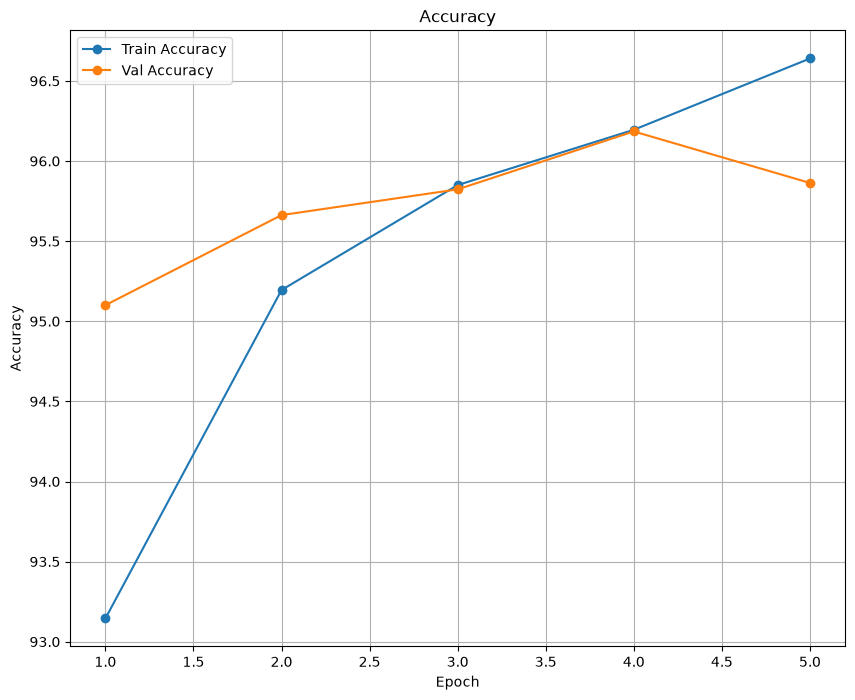

In [131]:
plt.figure(figsize=(10, 8))
plt.plot(epochs, train_accuracies_transfer, label='Train Accuracy', marker = 'o')
plt.plot(epochs, val_accuracies_transfer, label='Val Accuracy', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

In [132]:
mobile_net_v2 = models.mobilenet_v2(pretrained=True) #Обучал на ней свою модель для диплома, хороша для небольших датасетов
mobile_net_v2 = mobile_net_v2.features 

for param in mobile_net_v2.parameters():
    param.requires_grad = False

print(mobile_net_v2)

Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU6(inplace=True)
  )
  (1): InvertedResidual(
    (conv): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
  )
  (2): InvertedResidual(
    (conv): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bi

c:\Users\timep\AppData\Local\Programs\Python\Python314\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [133]:
class MobileNetV2TransferModel(nn.Module):
    def __init__(self, mobile_net_v2_features):
        super(MobileNetV2TransferModel, self).__init__()
        self.features = mobile_net_v2_features

        # MobileNetV2 стандартно использует глобальный пулинг 1x1
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # MobileNetV2 выдаёт 1280 каналов в последнем слое
        self.fc1 = nn.Linear(1280 * 1 * 1, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

modelV2 = MobileNetV2TransferModel(mobile_net_v2).to(device)
print(modelV2)

MobileNetV2TransferModel(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), b

In [134]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(modelV2.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [135]:
# Тоже самое

num_epochs_mobile = 5

# Lists to store training history
train_losses_mobile = []
train_accuracies_mobile = []
val_losses_mobile = []
val_accuracies_mobile = []

for epoch in range(num_epochs_mobile):
    modelV2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1) 

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = modelV2(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses_mobile.append(train_loss)
    train_accuracies_mobile.append(train_acc)

    # Validation phase
    modelV2.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = modelV2(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses_mobile.append(val_loss)
    val_accuracies_mobile.append(val_acc)

    print(f'Epoch [{epoch+1}/{num_epochs_mobile}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%') #Обучилось на 40 сек быстрее VGG-16, по точности на train видно, что она не перегружена параметрами как VGG, поэтому начинает с меньшей точностью


Epoch [1/5], Train Loss: 0.4770, Train Acc: 84.78%, Val Loss: 0.3126, Val Acc: 93.49%
Epoch [2/5], Train Loss: 0.2758, Train Acc: 91.61%, Val Loss: 0.2190, Val Acc: 94.02%
Epoch [3/5], Train Loss: 0.2183, Train Acc: 92.42%, Val Loss: 0.1820, Val Acc: 94.46%
Epoch [4/5], Train Loss: 0.1909, Train Acc: 93.10%, Val Loss: 0.1637, Val Acc: 94.22%
Epoch [5/5], Train Loss: 0.1789, Train Acc: 93.19%, Val Loss: 0.1520, Val Acc: 94.38%


In [136]:
# Evaluate transfer learning model on test data
modelV2.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = modelV2(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 94.80%


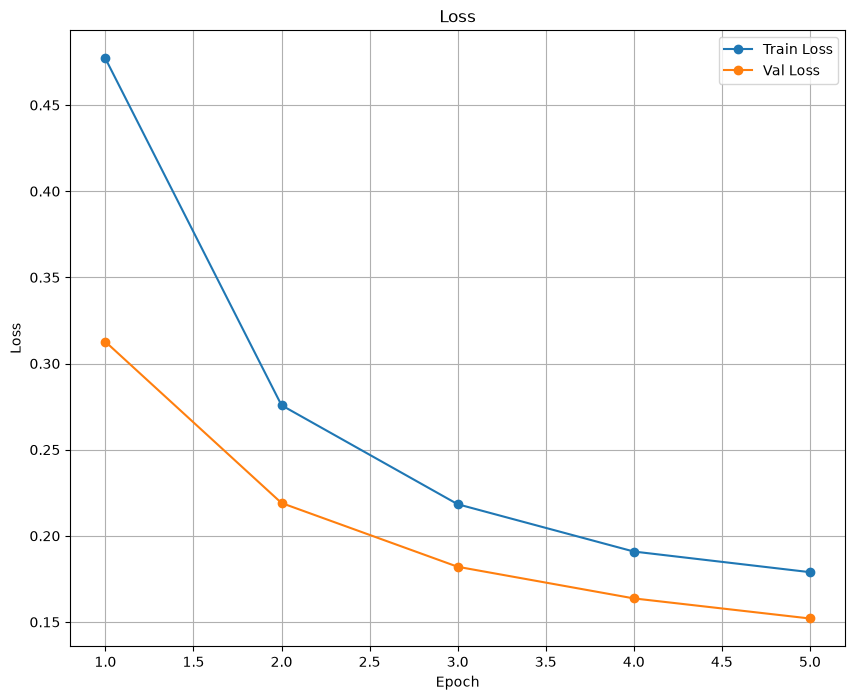

In [137]:
epochs = range(1, len(train_losses_mobile) + 1)

plt.figure(figsize=(10, 8))
plt.plot(epochs, train_losses_mobile, label='Train Loss', marker = 'o')
plt.plot(epochs, val_losses_mobile, label='Val Loss', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.grid(True)
plt.legend()
plt.show()

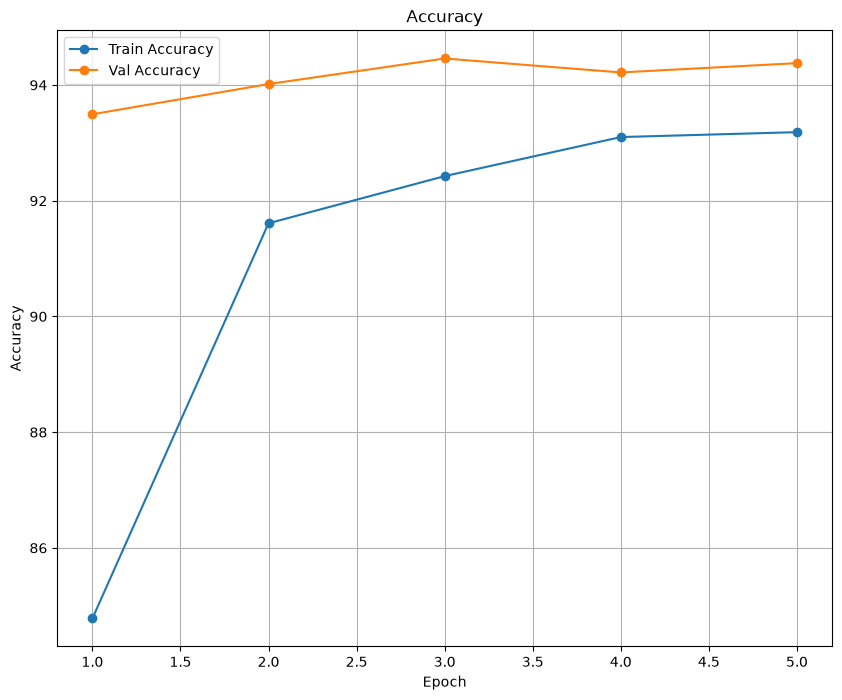

In [138]:
plt.figure(figsize=(10, 8))
plt.plot(epochs, train_accuracies_mobile, label='Train Accuracy', marker = 'o')
plt.plot(epochs, val_accuracies_mobile, label='Val Accuracy', marker = 'o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.grid(True)
plt.legend()
plt.show()

In [143]:
# TO FILL

# Function to predict whether a custom image is a cat or a dog
from PIL import Image

CLASS_NAMES = ["cat", "dog"]

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


def predict_image(image_path, model, device, class_names=CLASS_NAMES):
    """
    Predicts whether the image is a cat or a dog.

    Args:
        image_path: Path to the image file
        model: Trained PyTorch model
        device: torch device (CPU or CUDA)
        class_names: [class_for_logit_0, class_for_logit_1]

    Returns:
        Predicted class and probability (confidence)
    """
    model.eval()

    image = Image.open(image_path).convert("RGB")
    tensor = preprocess(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logit = model(tensor)
        prob  = torch.sigmoid(logit).item()

    if prob >= 0.5:
        predicted_class = class_names[1]
        confidence = prob
    else:
        predicted_class = class_names[0]
        confidence = 1.0 - prob

    return predicted_class, confidence


predicted_class, confidence = predict_image(r'C:\Users\timep\Downloads\Telegram Desktop\MLT-07 - CNNs\MLT-07 - CNNs\Cats_and_Dogs\val\cats\cat.11267.jpg', modelVGG, device)
print(f"VGG-16 Predicted: {predicted_class} with confidence {confidence*100:.2f}%")
predicted_class, confidence = predict_image(r'C:\Users\timep\Downloads\Telegram Desktop\MLT-07 - CNNs\MLT-07 - CNNs\Cats_and_Dogs\val\cats\cat.11267.jpg', modelV2, device)
print(f"MobileNetV2 Predicted: {predicted_class} with confidence {confidence*100:.2f}%")

VGG-16 Predicted: cat with confidence 99.88%
MobileNetV2 Predicted: cat with confidence 56.40%


## P.S.
Спасибо большое за этот курс, Вы очень понятно объясняли материал, поясняя даже простые вопросы. Благодаря Вам я стал лучше разбираться в теории(понял что надо подтягивать математику) и потихоньку писать код сам, к последней работе я уже автоматически писал код по памяти по некоторым участкам. Работы простые, чтобы войти в тему, мне действительно было интересно в них поразбираться, покопаться, в процессе было много вопросов "Это так работает?", после чего захватывал интерес искать информацию и разбираться в материале. Вы лучший преподаватель, было приятно слушать лекции! 